In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
# url='https://github.com/devtlv/DailyChallenge-DataAnalysis-W6D5-Mobile_Price_Classification/blob/main/train.csv'
# data description under: https://www.kaggle.com/code/farzadnekouei/noise-resilient-mobile-price-classification


In [5]:
df = pd.read_csv('/content/MobilePrice_classification_train.csv')

**1. Data Loading and Exploration:**

Utilize Pandas to load the dataset and explore its initial structure.

Summarize features, target variable, and their respective data types.

Conduct basic descriptive statistics for an overview of the dataset.

In [10]:
df.head(3)

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

All data is numeric, nothing is missing.

Target variable is the price range, and the rest - features explaining it.

In [13]:

# Let's check unique value counts - quite many binary:
for col in df.columns:
  print(f'{col}: {df[col].nunique()}')

battery_power: 1094
blue: 2
clock_speed: 26
dual_sim: 2
fc: 20
four_g: 2
int_memory: 63
m_dep: 10
mobile_wt: 121
n_cores: 8
pc: 21
px_height: 1137
px_width: 1109
ram: 1562
sc_h: 15
sc_w: 19
talk_time: 19
three_g: 2
touch_screen: 2
wifi: 2
price_range: 4


In [11]:
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


**2. Data Cleaning and Preprocessing:**

Address missing or null values.
Transform categorical data into numerical format using suitable methods.

In [14]:
# no missing values, everything is numerical

**3. Statistical Analysis with NumPy and SciPy:**

Execute detailed statistical analysis on each feature, including:
- Calculation of central tendency measures (mean, median, mode).
- Analysis of variability (range, variance, standard deviation).
- Evaluation of distribution shapes through skewness and kurtosis.
- Perform hypothesis testing for statistical significance between groups (e.g., different price ranges).
- Investigate feature-target correlations using SciPy
- Apply advanced SciPy statistical functions for deeper insights.

In [17]:
# Main statistics for each feature:
for col in df.columns:
  if col != 'price_range':
    print(f'Statistics on column {col}:')
    print(f"mean: {np.mean(df[col])}")
    print(f"median: {np.median(df[col])}")
    mode, count = stats.mode(df[col])
    print(f"mode: {mode}")
    print(f"min-max values: {np.min(df[col])} - {np.max(df[col])}")
    print(f"variance: {np.var(df[col])}")
    print(f"standard deviation: {np.std(df[col])}")
    print(f"Q1 {np.percentile(df[col],0.25)}, Q3 {np.percentile(df[col],0.75)}")
    IQR = np.percentile(df[col],0.75) - np.percentile(df[col],0.25)
    LB = np.percentile(df[col],0.25) - 1.5*(IQR)
    UB = np.percentile(df[col],0.75) + 1.5*(IQR)
    print(f"IQR {IQR}, [LB, UB]: [{LB}, {UB}]")
    print(f"skewness: {stats.skew(df[col])}")
    print(f"kurtosis: {stats.kurtosis(df[col])} \n")

Statistics on column battery_power:
mean: 1238.5185
median: 1226.0
mode: 618
min-max values: 501 - 1998
variance: 192991.81565774983
standard deviation: 439.3083377967573
Q1 503.0, Q3 507.9925
IQR 4.992500000000007, [LB, UB]: [495.51125, 515.48125]
skewness: 0.03187454295305568
kurtosis: -1.224084165725428 

Statistics on column blue:
mean: 0.495
median: 0.0
mode: 0
min-max values: 0 - 1
variance: 0.24997499999999545
standard deviation: 0.4999749993749642
Q1 0.0, Q3 0.0
IQR 0.0, [LB, UB]: [0.0, 0.0]
skewness: 0.02000100007500624
kurtosis: -1.9995999599959997 

Statistics on column clock_speed:
mean: 1.52225
median: 1.5
mode: 0.5
min-max values: 0.5 - 3.0
variance: 0.6655299375000027
standard deviation: 0.8158001823363382
Q1 0.5, Q3 0.5
IQR 0.0, [LB, UB]: [0.5, 0.5]
skewness: 0.17795052935349268
kurtosis: -1.3231094949498647 

Statistics on column dual_sim:
mean: 0.5095
median: 1.0
mode: 1
min-max values: 0 - 1
variance: 0.24990974999999974
standard deviation: 0.4999097418534667
Q1 0.0,

In [18]:
# checking count of different price ranges:
df['price_range'].value_counts()

,count
price_range,
1,500
2,500
3,500
0,500


Perfect - very balanced data set with respect price ranges having equal sample sizes of 500 each. We can apply ANOVA for hypothesis testing within these groups fpr each feature

In [23]:
# Grouping the data set by price range and checking which features have significantly different values in those groups
# This will help identify important features

alpha = 0.05
price_ranges = df['price_range'].unique()

important_features = []
for col in df.columns:
  if (col != 'price_range') and (df[col].nunique() > 2):
    f_stat, p_value = stats.f_oneway(*[df.loc[df['price_range'] == price,col].values for price in price_ranges])
    print(f"ANOVA on price-groups of {col}")
    print(f"f-statistics: {f_stat:.2f}, p-value: {p_value:.5f}")
    if p_value < alpha:
      print(f"H0 can be rejected, i.e. the feature {col} has singificant different values for different price ranges")
      important_features.append(col)
    else:
      print(f"H0 cannot be rejected, i.e. the feature {col} has no singificant different values for different price ranges")

    print("\n")
print(f"singificant features: {important_features}")

ANOVA on price-groups of battery_power
f-statistics: 31.60, p-value: 0.00000
H0 can be rejected, i.e. the feature battery_power has singificant different values for different price ranges


ANOVA on price-groups of clock_speed
f-statistics: 0.49, p-value: 0.68668
H0 cannot be rejected, i.e. the feature clock_speed has no singificant different values for different price ranges


ANOVA on price-groups of fc
f-statistics: 0.77, p-value: 0.50950
H0 cannot be rejected, i.e. the feature fc has no singificant different values for different price ranges


ANOVA on price-groups of int_memory
f-statistics: 2.92, p-value: 0.03278
H0 can be rejected, i.e. the feature int_memory has singificant different values for different price ranges


ANOVA on price-groups of m_dep
f-statistics: 1.50, p-value: 0.21246
H0 cannot be rejected, i.e. the feature m_dep has no singificant different values for different price ranges


ANOVA on price-groups of mobile_wt
f-statistics: 3.59, p-value: 0.01312
H0 can be re

In [61]:
# correlations with target variable price_range

target = df['price_range']
# corr_list = []
corr_arr = np.array([])
alpha=0.05

for col in df.columns:
  if col != 'price_range':
    feature = df[col]
    # Spearman
    corr, p_value = stats.spearmanr(feature, target)
    # corr_list.append((col, float(corr), float(p_value)))
    corr_arr = np.append(corr_arr,[corr])
    print(f"Spearman for {col}-price: ρ = {corr:.3f}, p = {p_value:.5f}, significant: {p_value < alpha}")

print(corr_arr)

Spearman for battery_power-price: ρ = 0.200, p = 0.00000, significant: True
Spearman for blue-price: ρ = 0.021, p = 0.35780, significant: False
Spearman for clock_speed-price: ρ = -0.005, p = 0.80804, significant: False
Spearman for dual_sim-price: ρ = 0.017, p = 0.43556, significant: False
Spearman for fc-price: ρ = 0.024, p = 0.28003, significant: False
Spearman for four_g-price: ρ = 0.015, p = 0.50910, significant: False
Spearman for int_memory-price: ρ = 0.044, p = 0.04772, significant: True
Spearman for m_dep-price: ρ = -0.000, p = 0.98852, significant: False
Spearman for mobile_wt-price: ρ = -0.030, p = 0.17680, significant: False
Spearman for n_cores-price: ρ = 0.005, p = 0.83532, significant: False
Spearman for pc-price: ρ = 0.033, p = 0.14227, significant: False
Spearman for px_height-price: ρ = 0.132, p = 0.00000, significant: True
Spearman for px_width-price: ρ = 0.165, p = 0.00000, significant: True
Spearman for ram-price: ρ = 0.917, p = 0.00000, significant: True
Spearman 

/tmp/ipykernel_5091/4082566372.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([col for col in df.columns.drop('price_range')], rotation=90)


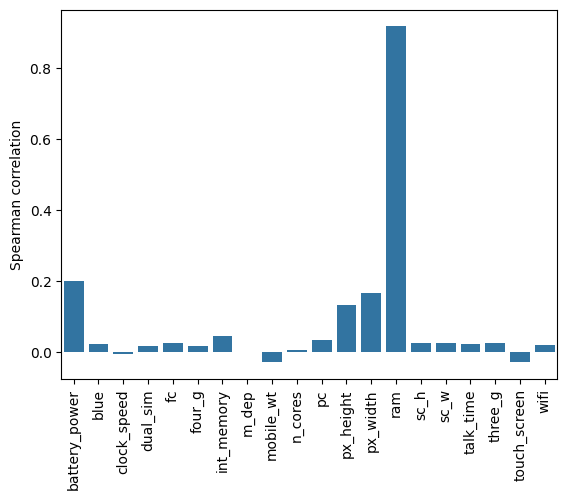

In [60]:
ax=sns.barplot(y=corr_arr, x=[col for col in df.columns.drop('price_range')])
#ax.set_xticks(range(len(corr_arr)))
ax.set_xticklabels([col for col in df.columns.drop('price_range')], rotation=90)
ax.set_ylabel('Spearman correlation')
plt.show()

As one can see from the correlation plots, the most important features should be `ram`, `battery_power`, `px_width`, `px_height` and based on ANOVA also `int_memory`, `mobile_wt` and `n_cores`

**4. Data Visualization with Matplotlib:**

Produce histograms, scatter plots, and box plots for data distribution and relationship insights.

Employ heatmaps for correlation visualization.

Ensure clarity in plots with appropriate titles, labels, and axis information.

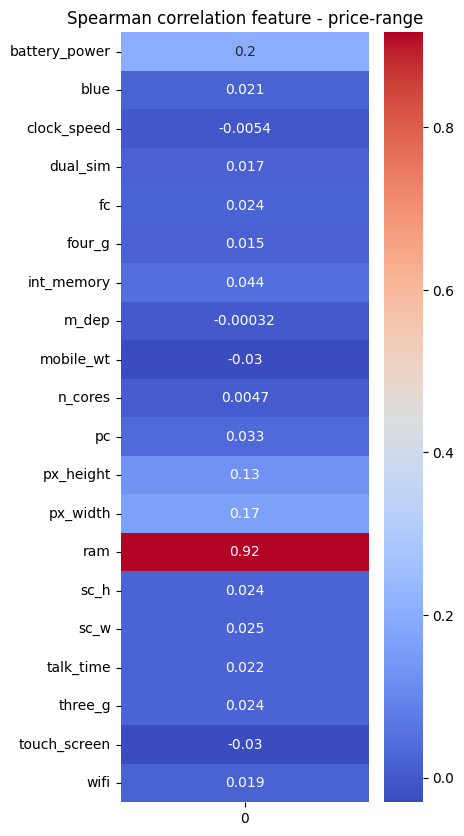

In [72]:
# heatmap for corr_arr
plt.figure(figsize=(4, 10))
ax = sns.heatmap(corr_arr.reshape(20,1), annot=True, cmap='coolwarm')
ax.set_yticklabels([col for col in df.columns.drop('price_range')], rotation=0)
plt.title("Spearman correlation feature - price-range")
plt.show()

**5. Insight Synthesis and Conclusion**:

Derive conclusions from statistical tests and visualizations.
Identify key determinants in mobile price classification.
Highlight any unexpected or significant findings.

Key determinats of price classes are: *ram, battery_power, px_width, px_height* and based on ANOVA also *int_memory, mobile_wt, n_cores*